## Basic agent ## 


Set Up code

In [99]:
from dotenv import load_dotenv
load_dotenv()
import os
api_key = os.getenv("OPENAI_API_KEY")

if api_key:
    print("OpenAI API Key is set.")
else:
    print("OpenAI API Key is missing.")





OpenAI API Key is set.


In [100]:
from langchain_openai import ChatOpenAI

llm_openai = ChatOpenAI(model='gpt-5-mini',temperature=0)
llm_openai.invoke("Hii").content



'Hi! How can I help you today? (You can ask a question, request writing or code, get a summary, translate, brainstorm, etc.)'

In [101]:
from typing import TypedDict
class graph_schema(TypedDict):
    question: str
    summery_question : str
    answer:str
    feedback:str
    is_correct: bool
    retry_count: int
    need_search:bool



In [102]:
from pydantic import BaseModel, Field

class evaluation_schema(BaseModel):
    is_correct: bool = Field(
        description="Whether the answer correctly and sufficiently answers the question."
    )
    feedback: str = Field(
        description="Explain what is missing or incorrect. Empty string if the answer is satisfactory."
    )

evaluator_llm = llm_openai.with_structured_output(evaluation_schema)

## Create a question Fixer ## 

In [103]:
from langchain_core.prompts import ChatPromptTemplate

def fix_question(state: graph_schema) -> graph_schema:

    user_question = state["question"]

    user_prompt = ChatPromptTemplate.from_messages([
        ("system", "You are a question corrector. Correct the user's grammar and spelling without changing the meaning."),
        ("human", "{user_question}")
    ])

    chain = user_prompt | llm_openai

    response = chain.invoke({
        "user_question": user_question
    })

    return {
        "question": response.content
    }



## Question Summery ##

In [104]:
from langchain_core.prompts import ChatPromptTemplate

def summery_question(state: graph_schema) -> graph_schema:

    user_question = state["question"]

    user_prompt = ChatPromptTemplate.from_messages([
        ("system", """
                You are a Question Summarization Agent.
                Understand the user's question and summarize it in one short sentence.
                Preserve the original intent and important details.
                Do not answer the question.
                Return only the summarized question.
        """),
        ("human", "{user_question}")
    ])

    chain = user_prompt | llm_openai

    response = chain.invoke({
        "user_question": user_question
    })

    return {
        "summery_question": response.content
    }



## Question Answer LLM ##

In [105]:
from langchain_core.prompts import ChatPromptTemplate

def answer_question(state: graph_schema) -> dict:

    user_question = state["question"]
    question_summary = state["summery_question"]

    user_prompt = ChatPromptTemplate.from_messages([
        ("system", """
            You are a helpful AI Question Answering Agent.

            Your task is to:
            1. Understand the user's original question.
            2. Use the question summary to understand the main intent.
            3. Provide an accurate, relevant, and easy-to-understand answer.
            4. Explain concepts with examples whenever helpful.
            5. If you don't know the answer, clearly say so.
            6. Do not simply repeat or summarize the question.
        """),
        ("human", """
            Original Question: {user_question}

            Question Summary: {question_summary}

            Feedback: {feedback}

            Please answer the original question.
        """)
    ])

    chain = user_prompt | llm_openai

    response = chain.invoke({
        "user_question": user_question,
        "question_summary": question_summary,
        "feedback": state["feedback"]
    })

    return {
        "answer": response.content
    }



create tool

In [106]:
from langchain_community.tools import DuckDuckGoSearchRun

duckduckgo_search = DuckDuckGoSearchRun()

# Test the tool
result = duckduckgo_search.invoke("Latest AI news in India")

print(result)

artificial intelligence in india Latest Breaking News, Pictures, Videos, and Special Reports from The Economic Times. artificial intelligence in india Blogs, Comments and Archive News on Economictimes.com Artificial Intelligence: Read latest updates on AI like Google AI, ChatGPT, Google Lamda, Bard chatbot and more along with latest news as AI technology advances and makes new progress. All get detailed articles on AI related queries like what is AI, types of artificial intelligence, its applications and future. india artificial intelligence news Latest Breaking News, Pictures, Videos, and Special Reports from The Economic Times. india artificial intelligence news Blogs, Comments and Archive News on Economictimes.com Artificial Intelligence (AI) News: Read more about the latest artificial intelligence news, and research, including web stories & videos at Gadgets News Artificial Intelligence Latest breaking news, pictures, photos and Video News. Find Artificial Intelligence news headlin

## answer_from_search

In [107]:
def answer_from_search(state: graph_schema) -> dict:

    print("DuckDuckGo Search Tool Called!")

    search_result = duckduckgo_search.invoke(state["question"])

    user_prompt = ChatPromptTemplate.from_messages([
        ("system", """
            You are an expert AI Research Assistant.

            Your task is to create a short but informative answer
            using the provided search results.

            Follow these rules:

            1. Start with a direct answer to the user's question.
            2. Use simple and easy-to-understand language.
            3. Keep the answer concise but informative.
            4. Include the most important facts and details.
            5. Use bullet points for multiple important details.
            6. Include dates, numbers, and examples when relevant.
            7. Avoid unnecessary introductions and repeated information.
            8. Do not make up information.
            9. If search results do not contain enough information,
               clearly mention that.

            Response format:
            - Direct answer
            - Important details (if needed)
            - Short conclusion (if needed)

            Keep the response around 100-150 words.
        """),
        ("human", """
            User Question:
            {question}

            Search Results:
            {search_result}

            Generate the final answer.
        """)
    ])

    chain = user_prompt | llm_openai

    response = chain.invoke({
        "question": state["question"],
        "search_result": search_result
    })

    return {
        "answer": response.content
    }

In [108]:
from pydantic import BaseModel,Field

class search_decision(BaseModel):
    need_search: bool =Field(description="True if external information is required; otherwise False.")
    reason:str = Field(description='Why external search is or is not needed.')

decision_llm = llm_openai.with_structured_output(search_decision)

Create a desaition node


In [109]:
def check_search(state:graph_schema)->graph_schema :
    prompt = ChatPromptTemplate.from_messages([
        ("system", """
            You decide whether a question needs internet search.

            Set need_search=True for:
            - Latest or current news information
            - Recent news and events
            - Live information
            - Information you cannot reliably answer from general knowledge

            Otherwise, set need_search=False.
        """),
        ("human", "{question}")
    ])
    chain = prompt | decision_llm

    response = chain.invoke({
        "question": state["question"]
    })
    
    return {
        "need_search": response.need_search
    }


## Evaluate Answer ##


In [110]:
def evaluate_answer(state: graph_schema) -> dict:

    evaluation_prompt = ChatPromptTemplate.from_messages([
        ("system", """
            You are an Answer Evaluation Agent.

            Evaluate the answer based on the original question.

            Check:
            1. Is the answer factually correct?
            2. Does it answer the actual question?
            3. Is important information missing?
            4. Is the answer clear and relevant?

            If the answer is correct and sufficient:
            - Set is_correct to True.
            - Set feedback to an empty string.

            Otherwise:
            - Set is_correct to False.
            - Provide specific feedback to improve the answer.
        """),
        ("human", """
            Question: {question}
            Answer: {answer}
        """)
    ])

    chain = evaluation_prompt | evaluator_llm

    response = chain.invoke({
        "question": state["question"],
        "answer": state["answer"]
    })

    return {
        "is_correct": response.is_correct,
        "feedback": response.feedback,
        "retry_count": state["retry_count"] + 1
    }

In [111]:
def check_answer(state: graph_schema) -> str:

    if state["is_correct"]:
        return "end"

    if state["retry_count"] >= 3:
        return "end"

    return "retry"

In [112]:
def route_search(state: graph_schema) -> str:

    if state["need_search"]:
        return "search"

    return "llm"

Connect the state

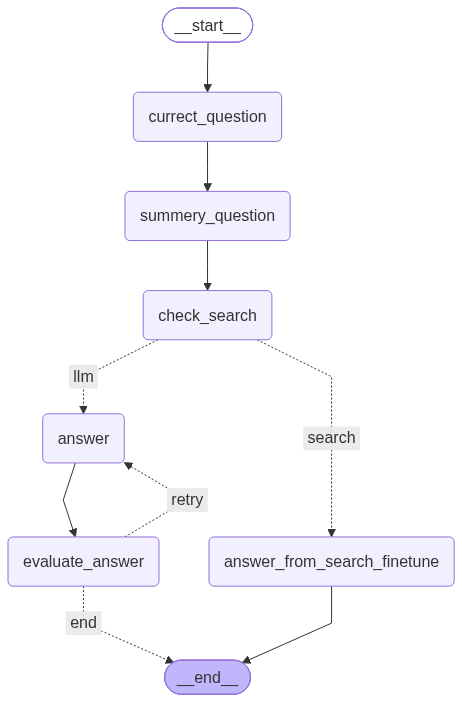

In [115]:
from langgraph.graph import StateGraph ,START, END

graph = StateGraph(graph_schema)
graph.add_node('currect_question',fix_question)
graph.add_node('summery_question',summery_question)
graph.add_node('check_search',check_search)
graph.add_node('answer',answer_question)
graph.add_node('answer_from_search_finetune',answer_from_search)
graph.add_node("evaluate_answer", evaluate_answer)


graph.add_edge(START,'currect_question')
graph.add_edge('currect_question','summery_question')
graph.add_edge('summery_question','check_search')
graph.add_conditional_edges('check_search',route_search,{
    'llm':'answer',
    "search": "answer_from_search_finetune"
})


graph.add_edge("answer",'evaluate_answer')
graph.add_conditional_edges('evaluate_answer',check_answer,{
    'end':END,
    'retry':'answer'
})

final_result = graph.compile()

from IPython.display import Image,display

Image(final_result.get_graph().draw_mermaid_png())

In [114]:
result = final_result.invoke({
    "question": "What is currect news for stockmarket?",
    "summery_question": "",
    "answer": "",
    "feedback": "",
    "is_correct": False,
    "retry_count": 0,
    "need_search": False
})

print("Corrected Question:", result["question"])
print("Question Summary:", result["summery_question"])
print("Final Answer:", result["answer"])
print("Is Correct:", result["is_correct"])
print("Feedback:", result["feedback"])
print("Retry Count:", result["retry_count"])
print("need_search:", result["need_search"])

DuckDuckGo Search Tool Called!
Corrected Question: What is the current news for the stock market?
Question Summary: What are the latest developments in the stock market?
Final Answer: Direct answer
- The search results don’t contain specific, up‑to‑the‑minute market headlines — they point to live news providers (Reuters, CNBC, The Economic Times) for current stock‑market coverage.

Important details
- Reuters: "Stock Market Today" offers breaking international market and finance news and updates throughout the trading session.  
- CNBC: provides in‑depth market analysis, real‑time data, research and earnings coverage.  
- The Economic Times: "Share Market Live" gives live charts, market updates, IPO news and local market movers.  
- For a quick snapshot, check: major indexes (S&P 500, Dow, Nasdaq), stock futures/pre‑market, top gainers/losers, economic calendar items, and earnings news.

Short conclusion
- Use one of the listed sites (Reuters, CNBC, Economic Times) or your broker’s rea